# CNN From Scratch — Distracted Driver Detection

Train a convolutional neural network to classify 10 driving
activities using the driver-based dataset split.

In [4]:
import torch
import pandas as pd 
import numpy as np
from pathlib import Path

#check PyTorch version
print("PyTorch version:", torch.__version__)


# Select available computing device
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")

print("Using device:", device)

PyTorch version: 2.14.1
Using device: mps


## Step 2 — Load Driver-Based Dataset

Load training and validation metadata and locate the original images.

In [5]:
# Load our saved dataset splits
train_df = pd.read_csv("../data/splits/driver_based/train.csv")
val_df = pd.read_csv("../data/splits/driver_based/val.csv")

# Folder containing the original images
image_root = Path(
    "../data/raw/state-farm-distracted-driver-detection/imgs/train"
)

# Create the complete image paths
for data in [train_df, val_df]:
    data["filepath"] = data.apply(
        lambda row: image_root / row["classname"] / row["img"],
        axis=1
    )

# Verify datasets
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("First image exists:", train_df.iloc[0]["filepath"].is_file())

Training images: 15732
Validation images: 3603
First image exists: True


## Step 3 — Create Dataset and DataLoader

Resize images to 128×128, convert them into tensors,
and organize them into batches of 32 for CNN training.

In [6]:
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Define image preprocessing
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# Create a custom PyTorch Dataset
class DriverDataset(Dataset):

    def __init__(self, dataframe, transform):
        self.data = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        row = self.data.iloc[idx]

        # Load image as RGB
        with Image.open(row["filepath"]) as img:
            image = img.convert("RGB")

        # Preprocess image
        image = self.transform(image)

        # Convert c0-c9 labels into integers 0-9
        label = int(row["classname"][1:])

        return image, label


# Create training and validation datasets
train_dataset = DriverDataset(train_df, transform)
val_dataset = DriverDataset(val_df, transform)

# Create DataLoaders
train_loader = DataLoader(
    train_dataset, batch_size=32, shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset, batch_size=32, shuffle=False,
    num_workers=0
)

# Inspect one batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)
print("First labels:", labels[:5])

Images shape: torch.Size([32, 3, 128, 128])
Labels shape: torch.Size([32])
First labels: tensor([1, 5, 0, 6, 9])


We won't use horizontal flipping as augmentation because it could change right-handed activities into left-handed ones, making the original labels incorrect.

## Step 4 — Build CNN Architecture

Create a convolutional neural network from scratch
to classify 10 distracted-driving activities.

In [7]:
import torch.nn as nn

class DriverCNN(nn.Module):

    def __init__(self):
        super().__init__()

        # Extract visual features
        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.AdaptiveAvgPool2d((4, 4))
        )

        # Classify extracted features
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


# Initialize model from scratch
torch.manual_seed(42)

model = DriverCNN().to(device)

print(model)

DriverCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (6): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (7): ReLU()
    (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (9): AdaptiveAvgPool2d(output_size=(4, 4))
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=2048, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)


In [8]:
# Pass one batch through the CNN
model.eval()

with torch.no_grad():
    outputs = model(images.to(device))

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

# Count trainable parameters
params = sum(p.numel() for p in model.parameters()
             if p.requires_grad)

print("Trainable parameters:", params)

Input shape: torch.Size([32, 3, 128, 128])
Output shape: torch.Size([32, 10])
Trainable parameters: 356810


In [9]:
import torch.optim as optim

# Measure classification errors
criterion = nn.CrossEntropyLoss()

# Update model parameters during training
optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

# Switch model to training mode
model.train()

print("Loss function and optimizer ready!")

Loss function and optimizer ready!


## Step 6 — CNN Training Loop

Train the CNN for one epoch using forward propagation,
cross-entropy loss, backpropagation, and Adam optimization.

In [10]:
import time
from tqdm import tqdm

# Switch to training mode
model.train()

total_loss = 0
correct = 0
total = 0

start = time.perf_counter()

# Loop through all training batches
for images, labels in tqdm(train_loader):

    # Move images and labels to GPU
    images = images.to(device)
    labels = labels.to(device)

    # Clear old gradients
    optimizer.zero_grad()

    # Forward pass: predict classes
    outputs = model(images)

    # Calculate prediction error
    loss = criterion(outputs, labels)

    # Backpropagation: calculate gradients
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Track training performance
    total_loss += loss.item() * images.size(0)
    correct += (outputs.argmax(dim=1) == labels).sum().item()
    total += labels.size(0)

# Calculate epoch statistics
epoch_loss = total_loss / total
epoch_accuracy = correct / total
training_time = time.perf_counter() - start

print(f"Training Loss: {epoch_loss:.4f}")
print(f"Training Accuracy: {epoch_accuracy:.2%}")
print(f"Training Time: {training_time:.2f} seconds")

100%|██████████| 492/492 [01:02<00:00,  7.91it/s]

Training Loss: 1.6266
Training Accuracy: 39.19%
Training Time: 62.22 seconds


## Step 7 — Validate CNN After First Epoch

Evaluate the CNN on unseen drivers without updating model parameters.

In [11]:
# Switch model to evaluation mode
model.eval()

val_loss = 0
correct = 0
total = 0

# Disable gradient calculations
with torch.no_grad():

    for images, labels in val_loader:

        # Move data to GPU
        images = images.to(device)
        labels = labels.to(device)

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Get predicted classes
        predictions = outputs.argmax(dim=1)

        # Accumulate results
        val_loss += loss.item() * images.size(0)
        correct += (predictions == labels).sum().item()
        total += labels.size(0)

# Calculate validation metrics
val_loss /= total
val_accuracy = correct / total

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2%}")

Validation Loss: 1.9724
Validation Accuracy: 44.38%


## Step 8 — Save CNN Checkpoint

Save model weights and training progress after the first epoch.

In [12]:
print("Model exists:", "model" in globals())
print("Optimizer exists:", "optimizer" in globals())
print("Training results exist:", "epoch_loss" in globals())

Model exists: True
Optimizer exists: True
Training results exist: True


In [13]:
# Create model directory
checkpoint_dir = Path("../models")
checkpoint_dir.mkdir(parents=True, exist_ok=True)

# Save training progress
torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_loss": epoch_loss,
    "train_accuracy": epoch_accuracy,
    "val_loss": val_loss,
    "val_accuracy": val_accuracy
}, checkpoint_dir / "cnn_scratch_epoch1.pt")

print("Epoch 1 checkpoint saved!")

Epoch 1 checkpoint saved!


## Step 9 — Multi-Epoch CNN Training

Continue training and automatically save model checkpoints.

In [14]:
import shutil
import time

# Keep epoch 1 as our initial best model
best_accuracy = val_accuracy
best_path = checkpoint_dir / "cnn_scratch_best.pt"
shutil.copyfile(
    checkpoint_dir / "cnn_scratch_epoch1.pt",
    best_path
)

history = []

# Continue training from epoch 2 to epoch 6
for epoch in range(2, 7):

    model.train()
    train_correct = 0
    train_total = 0
    start = time.perf_counter()

    # Training
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    train_acc = train_correct / train_total

    # Validation
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    val_acc = val_correct / val_total

    # Save latest checkpoint
    checkpoint = {
        "epoch": epoch,
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
        "val_accuracy": val_acc
    }

    torch.save(checkpoint, checkpoint_dir / "cnn_scratch_latest.pt")

    # Save best model
    if val_acc > best_accuracy:
        best_accuracy = val_acc
        torch.save(checkpoint, best_path)

    history.append({
        "epoch": epoch,
        "train_accuracy": train_acc,
        "val_accuracy": val_acc
    })

    print(
        f"Epoch {epoch} | "
        f"Train: {train_acc:.2%} | "
        f"Val: {val_acc:.2%} | "
        f"Time: {time.perf_counter() - start:.1f}s"
    )

print(f"Best validation accuracy: {best_accuracy:.2%}")

Epoch 2 | Train: 74.50% | Val: 52.73% | Time: 70.5s
Epoch 3 | Train: 85.71% | Val: 51.68% | Time: 68.6s
Epoch 4 | Train: 90.36% | Val: 52.10% | Time: 69.0s
Epoch 5 | Train: 93.26% | Val: 49.65% | Time: 67.3s
Epoch 6 | Train: 94.60% | Val: 57.29% | Time: 70.7s
Best validation accuracy: 57.29%


## Step 10 — Analyze Overfitting

Compare training and validation accuracy across epochs.

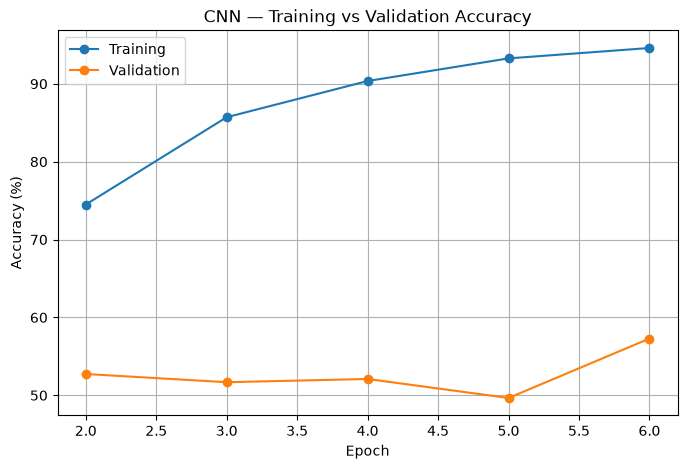

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert training history into a DataFrame
history_df = pd.DataFrame(history)

# Plot training and validation accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Training"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("CNN — Training vs Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

## Step 11 — Evaluate Best CNN

Load the best saved model and evaluate accuracy,
macro-F1, precision, and recall on unseen drivers.

In [16]:
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Load the best saved CNN
checkpoint = torch.load(
    "../models/cnn_scratch_best.pt",
    map_location=device,
    weights_only=True
)

# Create a model and restore its learned weights
best_model = DriverCNN().to(device)
best_model.load_state_dict(checkpoint["model_state_dict"])
best_model.eval()

# Store actual and predicted labels
y_true = []
y_pred = []

# Evaluate without updating weights
with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Calculate metrics
accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

print("Best epoch:", checkpoint["epoch"])
print(f"Validation Accuracy: {accuracy:.2%}")
print(f"Validation Macro-F1: {macro_f1:.4f}")

print("\nClassification Report:")
print(classification_report(y_true, y_pred))

Best epoch: 6
Validation Accuracy: 57.29%
Validation Macro-F1: 0.5583

Classification Report:
              precision    recall  f1-score   support

           0       0.46      0.70      0.56       372
           1       0.76      0.75      0.75       377
           2       0.59      0.16      0.25       367
           3       0.59      0.67      0.63       393
           4       0.44      0.42      0.43       378
           5       0.93      0.99      0.96       372
           6       0.37      0.49      0.42       372
           7       0.97      0.75      0.84       342
           8       0.33      0.54      0.41       298
           9       0.63      0.23      0.34       332

    accuracy                           0.57      3603
   macro avg       0.61      0.57      0.56      3603
weighted avg       0.61      0.57      0.56      3603

